<a href="https://colab.research.google.com/github/Richwalter/COU07506-labs/blob/main/WEEK_4_lab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

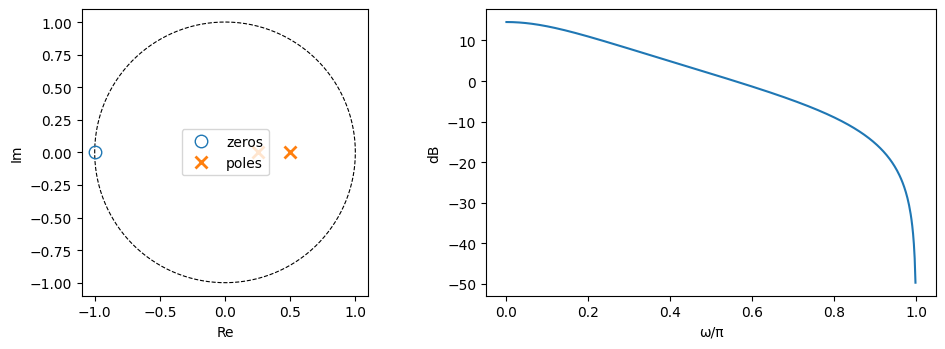

poles: [0.5  0.25]  stable: True


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

def zplane(b, a, ax=None):
    z, p, k = signal.tf2zpk(b, a)
    ax = ax or plt.gca()
    th = np.linspace(0, 2*np.pi, 400)
    ax.plot(np.cos(th), np.sin(th), "k--", lw=0.8)
    ax.plot(z.real, z.imag, "o", mfc="none", ms=9, label="zeros")
    ax.plot(p.real, p.imag, "x", ms=9, mew=2, label="poles")
    ax.set_aspect("equal")
    ax.legend()
    ax.set_xlabel("Re")
    ax.set_ylabel("Im")
    return z, p

# Coefficients
b, a = [1, 1], [1, -0.75, 0.125]

# Plotting
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.6))
z, p = zplane(b, a, ax1)

w, H = signal.freqz(b, a, worN=512)
ax2.plot(w/np.pi, 20*np.log10(np.abs(H)))
ax2.set_xlabel("ω/π")
ax2.set_ylabel("dB")
plt.tight_layout()
plt.show()

print("poles:", p, " stable:", np.all(np.abs(p) < 1))

In [2]:
import numpy as np
from scipy import signal

# --- Part 1: System with b = [1] and a = [1, -0.75, 0.125] ---
print("--- Part 1: b = [1], a = [1, -0.75, 0.125] ---")
r, p, k = signal.residuez([1], [1, -0.75, 0.125])
print("residues:", r)
print("poles:", p)

# Compute impulse response using partial fraction expansion (PFE)
n = np.arange(10)
x_pf = sum(ri * pi**n for ri, pi in zip(r, p)).real

# Compute impulse response using lfilter
impulse = np.zeros(10)
impulse[0] = 1
x_lf = signal.lfilter([1], [1, -0.75, 0.125], impulse)

print("PFE response:", x_pf)
print("lfilter response:", x_lf)
print("Are they close?", np.allclose(x_pf, x_lf))

# --- Part 2: System with b = [1, 1] (Task 4.1) ---
print("\n--- Part 2: b = [1, 1], a = [1, -0.75, 0.125] ---")
r_41, p_41, k_41 = signal.residuez([1, 1], [1, -0.75, 0.125])
print("residues:", r_41)
print("poles:", p_41)

# Compute numerical impulse response for Task 4.1
h_lf = signal.lfilter([1, 1], [1, -0.75, 0.125], impulse)

# Compute theoretical impulse response: h(n) = 6*(0.5)^n - 5*(0.25)^n
h_theoretical = 6 * (0.5)**n - 5 * (0.25)**n

print("Theoretical h(n):", h_theoretical)
print("lfilter h(n):    ", h_lf)
print("Does theoretical match lfilter?", np.allclose(h_theoretical, h_lf))

--- Part 1: b = [1], a = [1, -0.75, 0.125] ---
residues: [-1.  2.]
poles: [0.25 0.5 ]
PFE response: [1.         0.75       0.4375     0.234375   0.12109375 0.06152344
 0.03100586 0.01556396 0.00779724 0.00390244]
lfilter response: [1.         0.75       0.4375     0.234375   0.12109375 0.06152344
 0.03100586 0.01556396 0.00779724 0.00390244]
Are they close? True

--- Part 2: b = [1, 1], a = [1, -0.75, 0.125] ---
residues: [-5.  6.]
poles: [0.25 0.5 ]
Theoretical h(n): [1.         1.75       1.1875     0.671875   0.35546875 0.18261719
 0.0925293  0.04656982 0.02336121 0.01169968]
lfilter h(n):     [1.         1.75       1.1875     0.671875   0.35546875 0.18261719
 0.0925293  0.04656982 0.02336121 0.01169968]
Does theoretical match lfilter? True


### Task 4.3 — Pole position and the impulse response

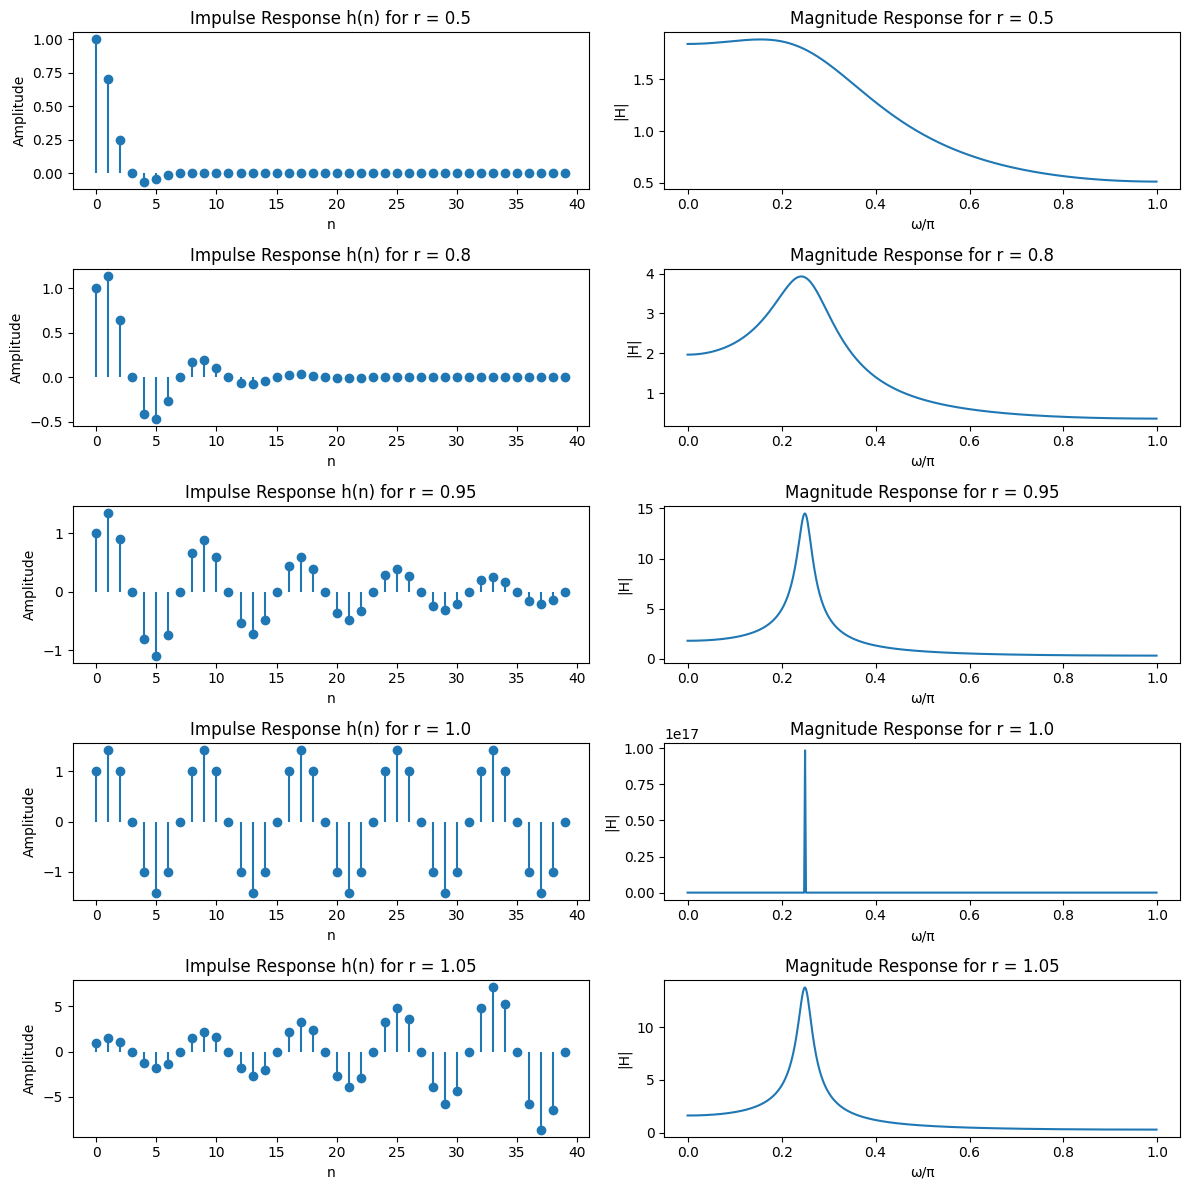

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

r_values = [0.5, 0.8, 0.95, 1.0, 1.05]
impulse = np.zeros(40)
impulse[0] = 1
n = np.arange(40)

fig, axes = plt.subplots(len(r_values), 2, figsize=(12, 12))

for i, r in enumerate(r_values):
    # A(z) = 1 - 2*r*cos(pi/4)*z^-1 + r^2*z^-2
    b = [1]
    a = [1, -2 * r * np.cos(np.pi / 4), r**2]

    # Impulse response
    h = signal.lfilter(b, a, impulse)

    # Frequency response
    w, H = signal.freqz(b, a, worN=512)

    # Plot h(n)
    axes[i, 0].stem(n, h, basefmt=" ")
    axes[i, 0].set_title(f"Impulse Response h(n) for r = {r}")
    axes[i, 0].set_xlabel("n")
    axes[i, 0].set_ylabel("Amplitude")

    # Plot |H(e^jw)|
    axes[i, 1].plot(w / np.pi, np.abs(H))
    axes[i, 1].set_title(f"Magnitude Response for r = {r}")
    axes[i, 1].set_xlabel("ω/π")
    axes[i, 1].set_ylabel("|H|")

plt.tight_layout()
plt.show()

### Task 4.4 — Stability of given systems

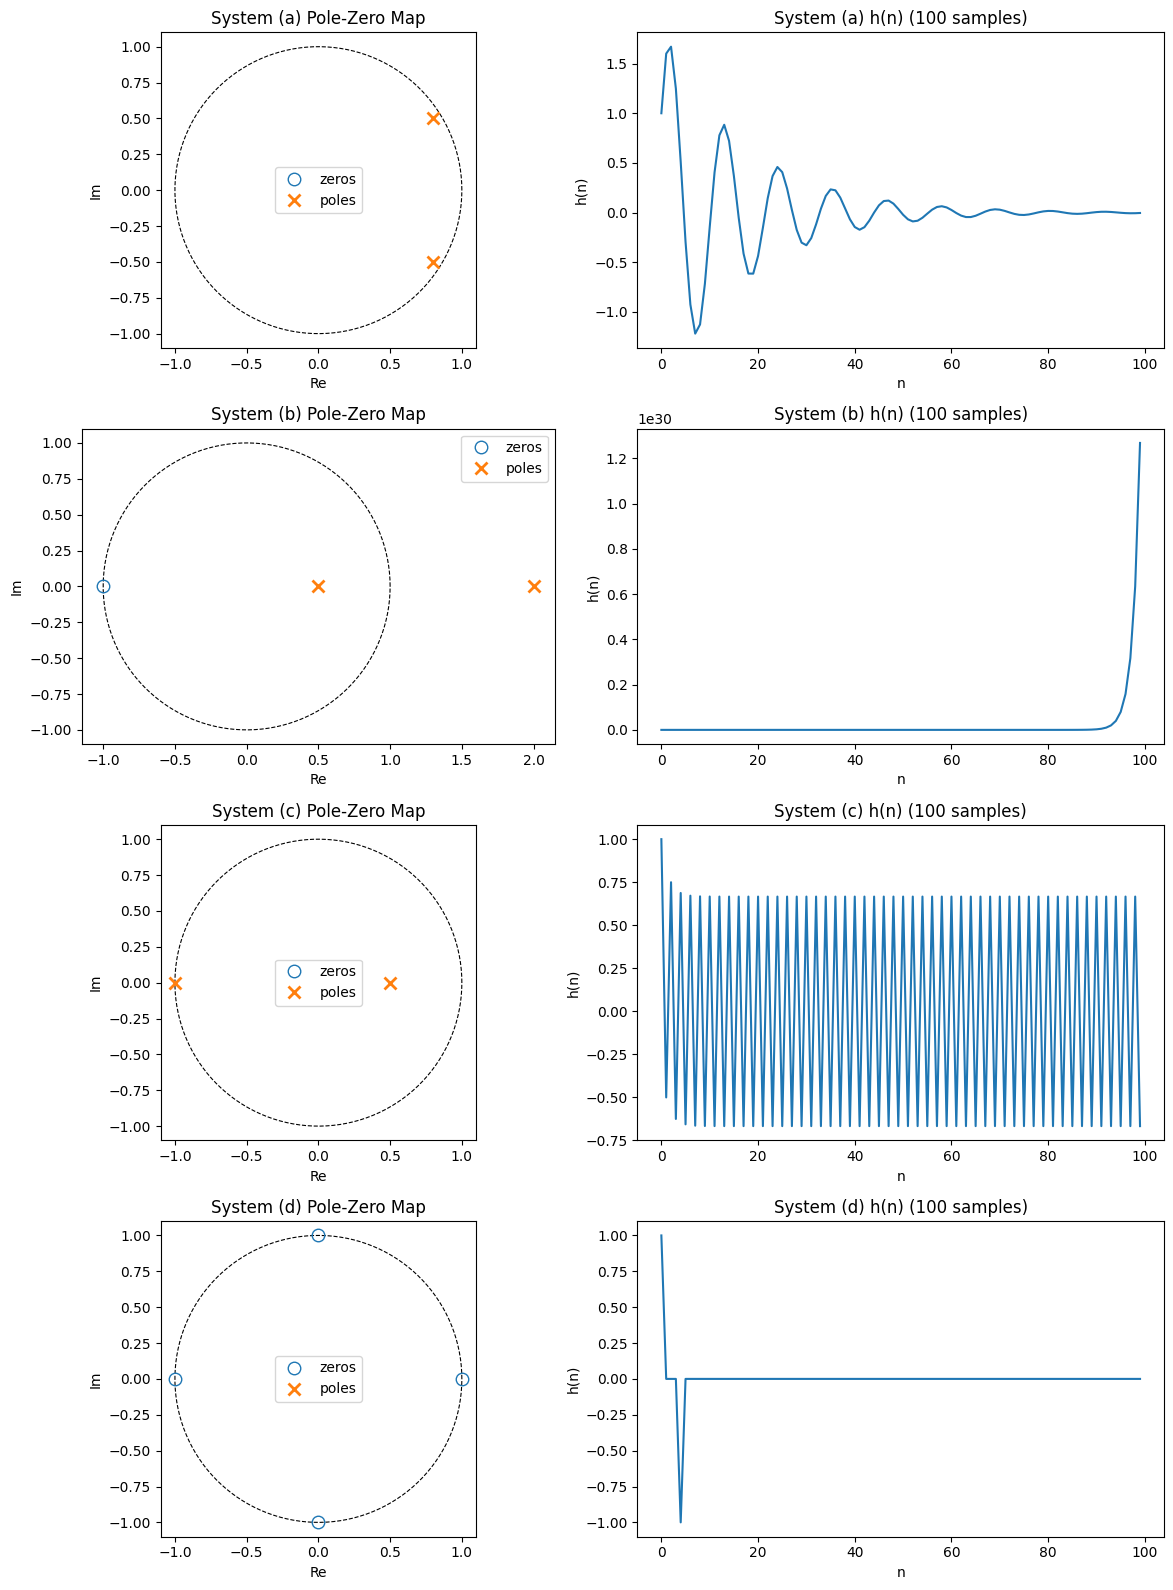

In [4]:
systems = {
    "(a)": ([1], [1, -1.6, 0.89]),
    "(b)": ([1, 1], [1, -2.5, 1]),
    "(c)": ([1], [1, 0.5, -0.5]),
    "(d)": ([1, 0, 0, 0, -1], [1])
}

fig, axes = plt.subplots(4, 2, figsize=(12, 16))
impulse_long = np.zeros(100)
impulse_long[0] = 1
n_long = np.arange(100)

for idx, (name, (b, a)) in enumerate(systems.items()):
    # Plot zplane on left
    ax_z = axes[idx, 0]
    zplane(b, a, ax_z)
    ax_z.set_title(f"System {name} Pole-Zero Map")

    # Simulate h(n) to check growth/decay on right
    h = signal.lfilter(b, a, impulse_long)
    ax_h = axes[idx, 1]
    ax_h.plot(n_long, h)
    ax_h.set_title(f"System {name} h(n) (100 samples)")
    ax_h.set_xlabel("n")
    ax_h.set_ylabel("h(n)")

plt.tight_layout()
plt.show()

### Task 4.5 — Design a resonator

/tmp/ipykernel_4148/4038298700.py:35: RuntimeWarning: divide by zero encountered in log10
  ax2.plot(f, 20 * np.log10(np.abs(H)))


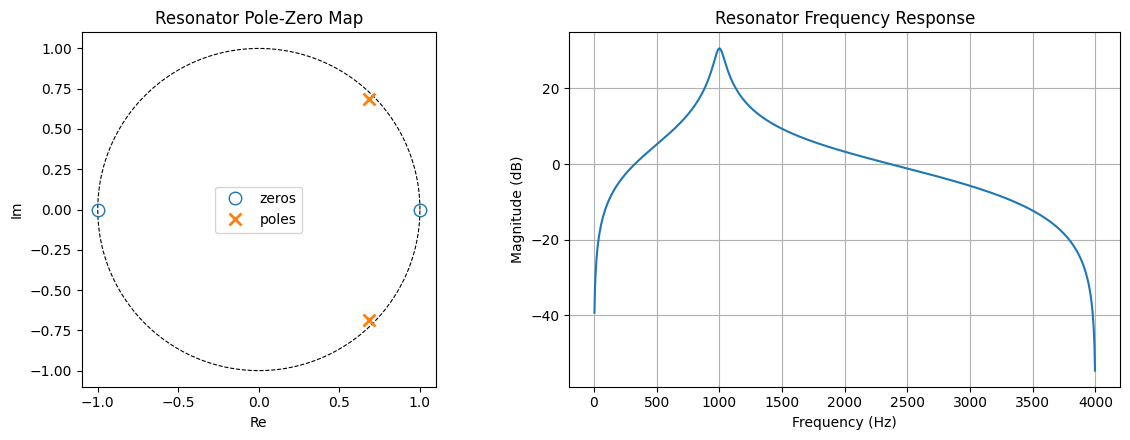

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from IPython.display import Audio

# Specifications
fs = 8000.0
f_peak = 1000.0
r = 0.97

# Angular frequency theta
theta = 2 * np.pi * f_peak / fs  # equals pi / 4

# Poles and Zeros
# Poles: r * e^(+- j * theta)
poles = [r * np.exp(1j * theta), r * np.exp(-1j * theta)]
# Zeros: at z = 1 (blocks DC) and z = -1 (blocks fs/2)
zeros = [1.0, -1.0]

# Find polynomial coefficients
b = np.poly(zeros)  # equivalent to [1, 0, -1]
a = np.poly(poles)  # equivalent to [1, -2*r*cos(theta), r^2]

# Plot Pole-Zero Map and Frequency Response
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))

# Plot zplane
zplane(b, a, ax1)
ax1.set_title("Resonator Pole-Zero Map")

# Plot Frequency Response in Hz
w, H = signal.freqz(b, a, worN=1024)
f = (w * fs) / (2 * np.pi)

ax2.plot(f, 20 * np.log10(np.abs(H)))
ax2.set_title("Resonator Frequency Response")
ax2.set_xlabel("Frequency (Hz)")
ax2.set_ylabel("Magnitude (dB)")
ax2.grid(True)
plt.tight_layout()
plt.show()

In [7]:
import soundfile as sf
from scipy import signal
from IPython.display import Audio

# Load the custom WAV file
audio_data, fs_loaded = sf.read('/content/walter.wav')

# Ensure mono audio for simpler filtering if it's stereo
if len(audio_data.shape) > 1:
    audio_data = audio_data[:, 0]

# Apply the resonator filter
y = signal.lfilter(b, a, audio_data)

# Listen to the output (using the loaded sample rate, or forcing fs if required)
Audio(y, rate=int(fs_loaded))

         Analysis Answers

1. Increasing rrr moves the poles closer to the unit circle, producing a narrower bandwidth and a sharper resonance. Decreasing rrr gives a wider bandwidth.

2. When a pole is exactly on the unit circle (r=1r=1r=1), the impulse response does not decay and oscillates indefinitely, making the system not BIBO stable.

3. Zeros at z=±1z=\pm1z=±1 force the response to zero at DC and the Nyquist frequency, removing low and high frequencies and leaving a band around the resonant frequency, producing a band-pass filter.

4. According to the stability triangle, poles inside the unit circle are stable, poles on the unit circle are marginally stable, and poles outside the unit circle are unstable.